# LeetCode #1063: Valid Triangles

https://leetcode.com/problems/valid-triangles/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n^3)$ | $O(1)$ |
| **Optimal: Sort + Two Pointers ★** | $O(n^2)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
Try every triple $(i, j, k)$ and verify the triangle inequality for all three pairs of sides. Three nested loops give $O(n^3)$ comparisons.

### Optimal: Sort + Two Pointers ★
Sort the array. For each fixed largest side at index $k$, use two pointers $i$ and $j$ (starting at 0 and $k-1$) to count pairs where $nums[i] + nums[j] > nums[k]$. Sorting lets us skip many invalid pairs at once, reducing the inner work to $O(n)$ per $k$.

**Why this is better than Brute Force:** Sorting enables the two-pointer skip — when $nums[i]+nums[j] > nums[k]$, all pairs between $i$ and $j$ also satisfy the condition, so we count $j-i$ at once instead of testing each pair individually.

**Constraints:**
* $1 \leq nums.length \leq 1000$
* $0 \leq nums[i] \leq 1000$


## Solutions

### C#


In [ ]:
public int TriangleNumber(int[] nums) {
    Array.Sort(nums);
    int count = 0, n = nums.Length;
    // Fix the largest side and use two pointers on the remaining prefix
    for (int k = n - 1; k >= 2; k--) {
        int i = 0, j = k - 1;
        while (i < j) {
            // Both pointers together exceed the largest side — all pairs i..j-1 are valid
            if (nums[i] + nums[j] > nums[k]) {
                count += j - i;
                j--;
            } else {
                // Sum too small; advance left pointer to increase it
                i++;
            }
        }
    }
    return count;
}


### Python


In [ ]:
def triangle_number(nums: list[int]) -> int:
    nums.sort()
    count, n = 0, len(nums)
    # Fix the largest side; two pointers find valid shorter-side pairs
    for k in range(n - 1, 1, -1):
        i, j = 0, k - 1
        while i < j:
            if nums[i] + nums[j] > nums[k]:
                # All indices between i and j form valid triangles with nums[k]
                count += j - i
                j -= 1
            else:
                i += 1
    return count


### Go


In [ ]:
import "sort"

func triangleNumber(nums []int) int {
    sort.Ints(nums)
    count, n := 0, len(nums)
    // Fix largest side at k, shrink window with two pointers
    for k := n - 1; k >= 2; k-- {
        i, j := 0, k-1
        for i < j {
            if nums[i]+nums[j] > nums[k] {
                // Positions i through j-1 all pair validly with j
                count += j - i
                j--
            } else {
                i++
            }
        }
    }
    return count
}


### Rust


In [ ]:
pub fn triangle_number(mut nums: Vec<i32>) -> i32 {
    nums.sort_unstable();
    let n = nums.len();
    let mut count = 0;
    // For each largest side, shrink two-pointer window to count valid pairs
    for k in (2..n).rev() {
        let (mut i, mut j) = (0usize, k - 1);
        while i < j {
            if nums[i] + nums[j] > nums[k] {
                // Every index from i to j-1 pairs with j to beat nums[k]
                count += (j - i) as i32;
                j -= 1;
            } else {
                i += 1;
            }
        }
    }
    count
}


## Example Scenarios

### 1. Common Case — One Degenerate Pair
**Input:** `nums = [2, 2, 3, 4]`

Sorted it is already $[2,2,3,4]$. Fix $k = 3$ (largest side 4): $i = 0, j = 2$ gives $2 + 3 = 5 > 4$, so every index in $[i, j)$ pairs with $j$ — add $j - i = 2$ and drop $j$ to 1; then $2 + 2 = 4 \not> 4$, so $i$ advances and the window closes. Fix $k = 2$ (side 3): $2 + 2 = 4 > 3$, add 1. Total **3**. The pair $(2,2,4)$ is the one rejected — it is degenerate, not a triangle.

### 2. Slightly Complex — Mixed Advances
**Input:** `nums = [1, 2, 3, 4, 5, 6]`

Ten pointer steps in all, alternating between `i++` (too short) and a bulk `count += j - i`. The running count goes $0 \to 3 \to 4 \to 6 \to 7$, finishing at **7**: $(2,3,4), (2,4,5), (3,4,5), (2,5,6), (3,5,6), (4,5,6), (3,4,6)$. Note that side 1 never participates — $1 + x > y$ fails for every larger pair.

### 3. Edge Case: Time Factor — Every Side Identical
**Input:** `nums = [1, 1, 1, 1, 1, 1]`

Every triple works, so for each $k$ the pointer $i$ never moves and $j$ walks all the way down: $k - 1$ steps per $k$, $\sum_{k} (k-1) = O(n^2)$ total — the algorithm's worst case. Count $= \binom{6}{3} = $ **20**. At the constraint limit $n = 1000$ the answer is $\binom{1000}{3} = 166{,}167{,}000$, which still fits in a 32-bit signed int (max $\approx 2.15 \times 10^9$).

### 4. Edge Case: Space Factor — All Zeros, Nothing Ever Counted
**Input:** `nums = [0, 0, 0, 0]`

$0 + 0 = 0 \not> 0$, so every comparison fails and `i` is the only pointer that ever moves; the count stays **0**. Space is the point here: the sort is in place and the only extra state is `count, i, j, k`, so $O(1)$ auxiliary memory — the $O(n^3)$ brute force is no better on space, only far worse on time.

### 5. Almost-Impossible but Plausible — Both Boundary Values at Once
**Input:** `nums = [0, 1000, 1000, 1000, 1]` → sorted `[0, 1, 1000, 1000, 1000]`

Both ends of the $0 \le nums[i] \le 1000$ range appear in one array. The 0 can never form a triangle, since $0 + x > y$ is false whenever $x \le y$. The 1 does work, but only alongside two 1000s: $1 + 1000 = 1001 > 1000$. The trace is `i++`, add 2, add 1 for $k = 4$; `i++`, add 1 for $k = 3$; `i++` for $k = 2$ — total **4**, namely $(1,1000,1000)$ in three index combinations plus $(1000,1000,1000)$. Every rejection comes from the strict inequality, which is also why the all-zero array in example 4 scores nothing.

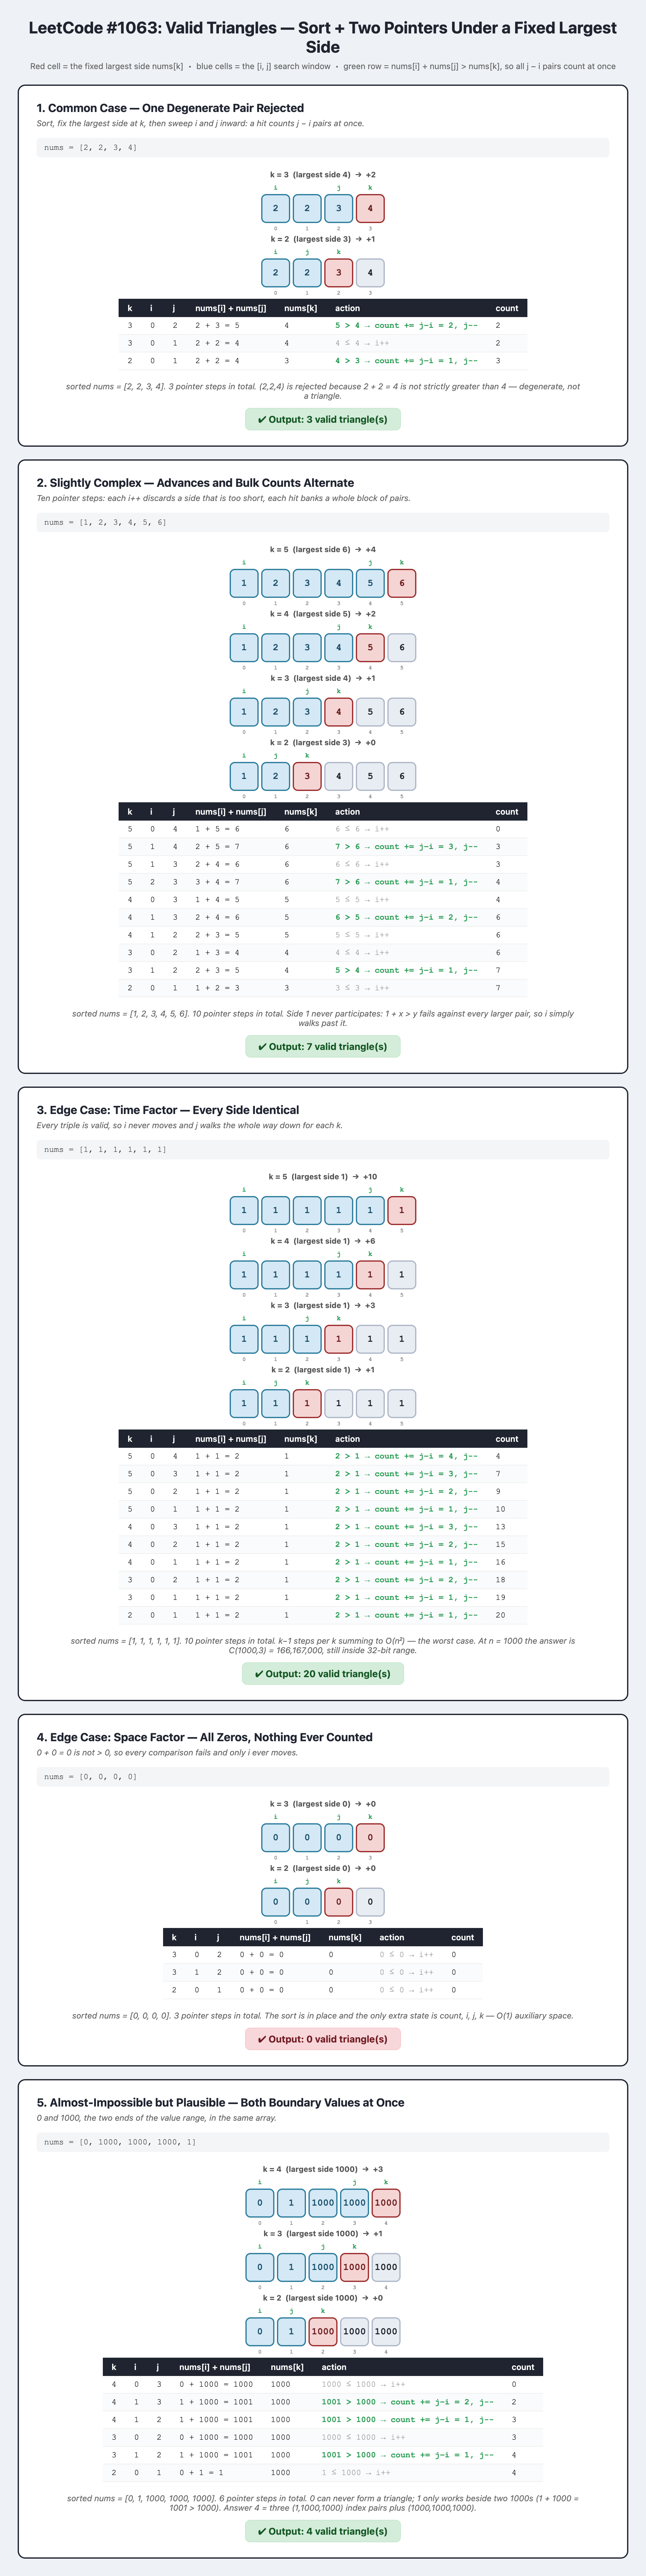